In [13]:
import os
import subprocess

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from entsoe import EntsoePandasClient
from entsoe.mappings import Area

api_key = subprocess.run(
    ["security", "find-generic-password", "-a", os.environ["USER"], "-s", "wind_de", "-w"],
    capture_output=True,
    text=True,
    check=True,
).stdout.strip()

load_dotenv("../.env")
client = EntsoePandasClient(api_key=api_key)

ZONES = {
    "50Hertz": "DE_50HZ",
    "Amprion": "DE_AMPRION",
    "TenneT": "DE_TENNET",
    "TransnetBW": "DE_TRANSNET",
}

for zone, code in ZONES.items():
    print(zone, Area[code].code)

50Hertz 10YDE-VE-------2
Amprion 10YDE-RWENET---I
TenneT 10YDE-EON------1
TransnetBW 10YDE-ENBW-----N


In [14]:
start = pd.Timestamp("2026-10-12", tz="Europe/Berlin")
end = pd.Timestamp("2026-10-19", tz="Europe/Berlin")

frames = []
for zone, code in ZONES.items():
    raw = client.query_generation(code, start=start, end=end)
    if isinstance(raw.columns, pd.MultiIndex):
        raw = raw.xs("Actual Aggregated", axis=1, level=1)
    wind = raw.reindex(columns=["Wind Onshore", "Wind Offshore"])
    wind["zone"] = zone
    frames.append(wind)

actual = pd.concat(frames)
actual.head(10)

,Wind Onshore,Wind Offshore,zone
2026-10-12 00:00:00+02:00,6795.36,1183.01,50Hertz
2026-10-12 00:15:00+02:00,6752.29,1088.89,50Hertz
2026-10-12 00:30:00+02:00,6699.80,1081.46,50Hertz
2026-10-12 00:45:00+02:00,6648.40,979.18,50Hertz
2026-10-12 01:00:00+02:00,6539.42,921.82,50Hertz
2026-10-12 01:15:00+02:00,6428.92,1026.56,50Hertz
2026-10-12 01:30:00+02:00,6421.44,1091.37,50Hertz
2026-10-12 01:45:00+02:00,6437.03,1022.54,50Hertz
2026-10-12 02:00:00+02:00,6398.75,968.89,50Hertz
2026-10-12 02:15:00+02:00,6277.31,980.22,50Hertz


In [15]:
print(actual.groupby("zone")[["Wind Onshore", "Wind Offshore"]].describe().round(0))
print(actual.groupby("zone").apply(lambda d: d.index.to_series().diff().value_counts()))

           Wind Onshore                                                 \
                  count    mean     std    min     25%     50%     75%   
zone                                                                     
50Hertz           672.0  3673.0  2446.0  279.0  1584.0  3018.0  5400.0   
Amprion           672.0  2229.0  1413.0   59.0  1133.0  1888.0  3533.0   
TenneT            672.0  6148.0  3153.0  228.0  4320.0  6067.0  8342.0   
TransnetBW        672.0   161.0   166.0   11.0    24.0   102.0   239.0   

                    Wind Offshore                                       \
                max         count    mean     std  min     25%     50%   
zone                                                                     
50Hertz      9263.0         672.0  1056.0   685.0  0.0   427.0  1027.0   
Amprion      6366.0           0.0     NaN     NaN  NaN     NaN     NaN   
TenneT      14388.0         672.0  3764.0  1550.0  5.0  3248.0  4254.0   
TransnetBW    684.0           0.0    

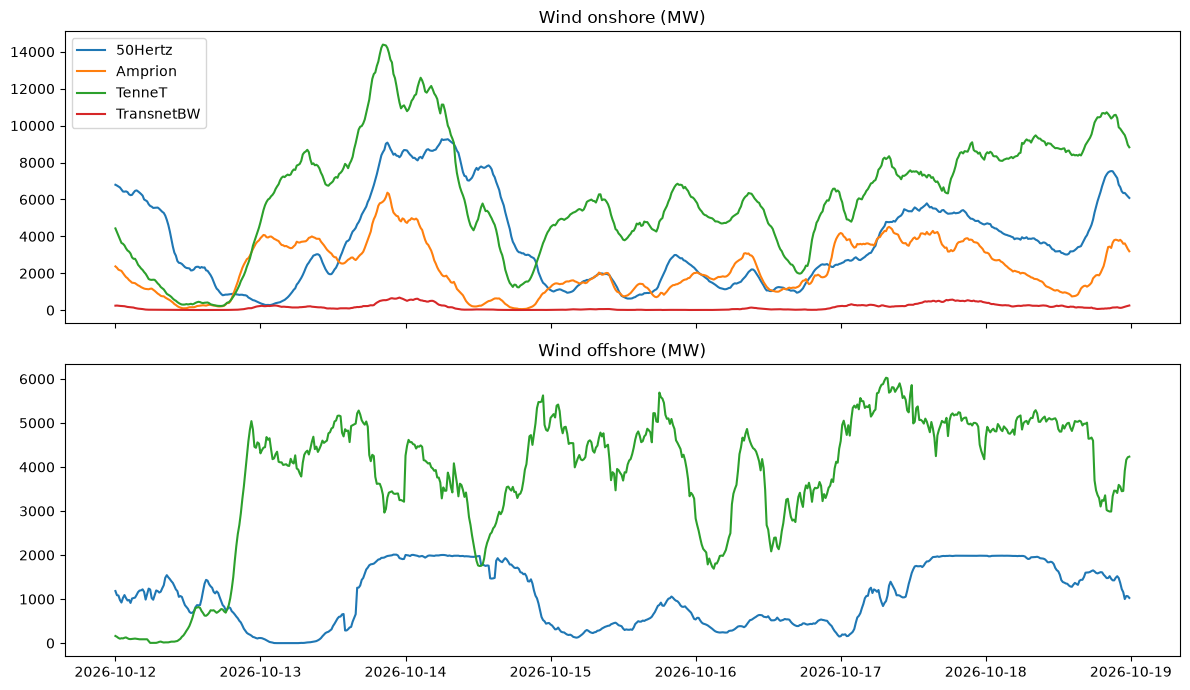

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for zone, d in actual.groupby("zone"):
    axes[0].plot(d.index, d["Wind Onshore"], label=zone)
    axes[1].plot(d.index, d["Wind Offshore"], label=zone)
axes[0].set_title("Wind onshore (MW)")
axes[1].set_title("Wind offshore (MW)")
axes[0].legend()
plt.tight_layout()

In [17]:
fc_frames = []
for zone, code in ZONES.items():
    fc = client.query_wind_and_solar_forecast(code, start=start, end=end)
    fc = fc.reindex(columns=["Wind Onshore", "Wind Offshore"])
    fc["zone"] = zone
    fc_frames.append(fc)

forecast = pd.concat(fc_frames)
print(forecast.groupby("zone").apply(lambda d: d.index.to_series().diff().value_counts()))
forecast.head()

count       0 days 00:15:00
zone                       
50Hertz                 671
Amprion                 671
TenneT                  671
TransnetBW              671


,Wind Onshore,Wind Offshore,zone
2026-10-12 00:00:00+02:00,6861.93,792.39,50Hertz
2026-10-12 00:15:00+02:00,6768.45,801.12,50Hertz
2026-10-12 00:30:00+02:00,6674.27,809.91,50Hertz
2026-10-12 00:45:00+02:00,6582.77,819.24,50Hertz
2026-10-12 01:00:00+02:00,6492.80,829.92,50Hertz


Mean absolute error (MW): 506


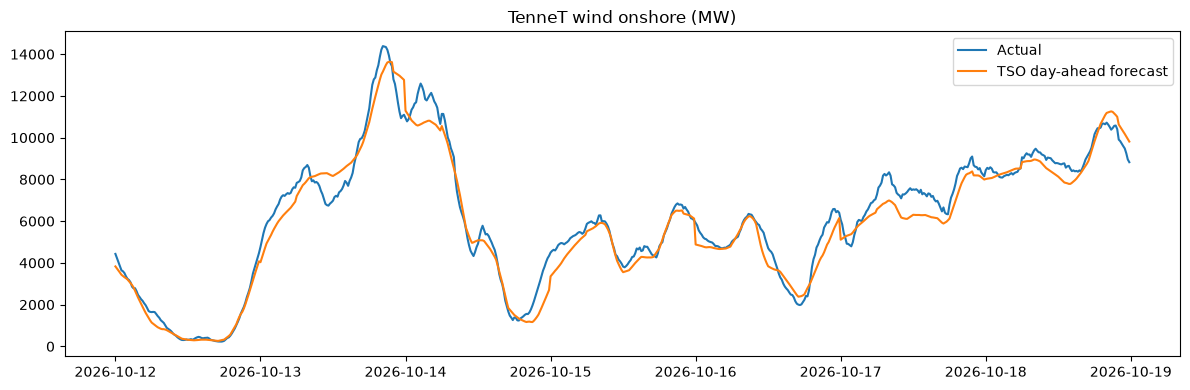

In [18]:
z = "TenneT"
a = actual.loc[actual.zone == z, "Wind Onshore"]
f = forecast.loc[forecast.zone == z, "Wind Onshore"]

plt.figure(figsize=(12, 4))
plt.plot(a.index, a, label="Actual")
plt.plot(f.index, f, label="TSO day-ahead forecast")
plt.title(f"{z} wind onshore (MW)")
plt.legend()
plt.tight_layout()

print("Mean absolute error (MW):", round((f - a).abs().mean()))